In [2]:
# JulioPrajaSarbunan_202431152
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('heart.csv')
target = 'HeartDisease'
print(df.shape)
df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [5]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [6]:
fitur_num = df.select_dtypes(include='number').columns.drop(target).tolist()
print('Jumlah fitur numerik:', len(fitur_num))
print(fitur_num)

Jumlah fitur numerik: 6
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']


In [7]:
fitur_kat = df.select_dtypes(include=['object', 'string']).columns.tolist()
print('Jumlah fitur kategorikal:', len(fitur_kat))
print(fitur_kat)

Jumlah fitur kategorikal: 5
['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


In [8]:
for k in fitur_kat:
    print(k, '->', df[k].unique())

Sex -> ['M' 'F']
ChestPainType -> ['ATA' 'NAP' 'ASY' 'TA']
RestingECG -> ['Normal' 'ST' 'LVH']
ExerciseAngina -> ['N' 'Y']
ST_Slope -> ['Up' 'Flat' 'Down']


In [9]:
from sklearn.preprocessing import LabelEncoder
encoders = {}
for k in fitur_kat:
    encoders[k] = LabelEncoder()
    df[k] = encoders[k].fit_transform(df[k])
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0


In [10]:
x = df.drop(target, axis=1)
y = df[target]

In [11]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)

In [12]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(x_train, y_train)

GaussianNB()

In [13]:
pred_train = model.predict(x_train)
pred_test = model.predict(x_test)

Evaluasi Training
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       318
           1       0.88      0.86      0.87       370

    accuracy                           0.86       688
   macro avg       0.86      0.86      0.86       688
weighted avg       0.86      0.86      0.86       688



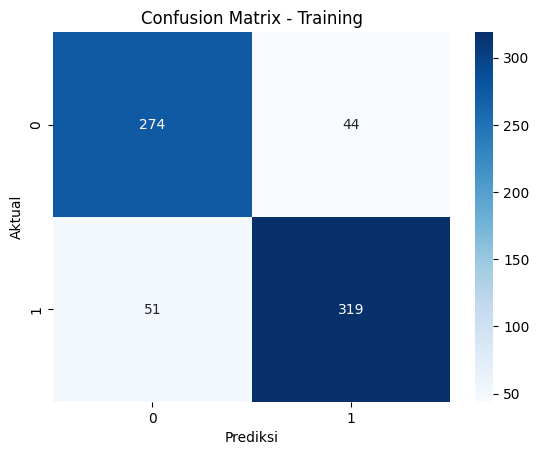

In [14]:
from sklearn.metrics import confusion_matrix, classification_report
print('Evaluasi Training')
print(classification_report(y_train, pred_train))
sns.heatmap(confusion_matrix(y_train, pred_train), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Training')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

Evaluasi Testing
              precision    recall  f1-score   support

           0       0.82      0.79      0.81        92
           1       0.87      0.88      0.87       138

    accuracy                           0.85       230
   macro avg       0.84      0.84      0.84       230
weighted avg       0.85      0.85      0.85       230



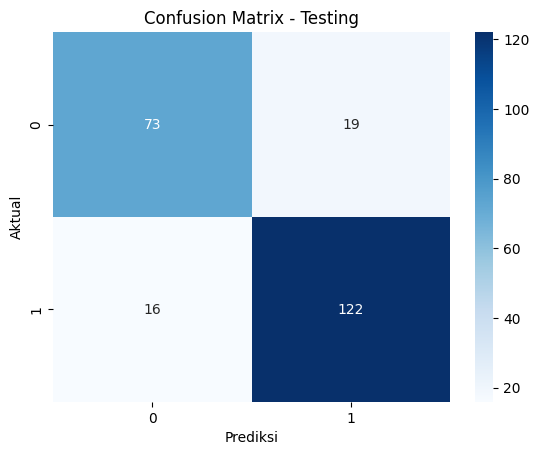

In [15]:
print('Evaluasi Testing')
print(classification_report(y_test, pred_test))
sns.heatmap(confusion_matrix(y_test, pred_test), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Testing')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

In [16]:
baru = {
    'Age': 55, 'Sex': 'M', 'ChestPainType': 'ASY', 'RestingBP': 140,
    'Cholesterol': 230, 'FastingBS': 0, 'RestingECG': 'Normal', 'MaxHR': 120,
    'ExerciseAngina': 'Y', 'Oldpeak': 1.5, 'ST_Slope': 'Flat'
}
data_baru = pd.DataFrame([baru])
for k in fitur_kat:
    data_baru[k] = encoders[k].transform(data_baru[k])
data_baru = data_baru[x.columns]
hasil = model.predict(data_baru)
print('Hasil prediksi:', hasil)

Hasil prediksi: [1]
